# Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = [15, 8]

# Load data

In [2]:
DATA_DIR = '../../data/other_data/'

In [59]:
filename = DATA_DIR + "electricity.csv"
df = pd.read_csv(filename, index_col='time', header=0, parse_dates=True, date_format='%Y-%m-%d %H:%M:%S')
df

C:\Users\HP\AppData\Local\Temp\ipykernel_20712\4065306165.py:2: DtypeWarning: Columns (1,2,3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filename, index_col='time', header=0, parse_dates=True, date_format='%Y-%m-%d %H:%M:%S')


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
time,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
2006-12-16 17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2006-12-16 17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
2006-12-16 17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
2006-12-16 17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0
...,...,...,...,...,...,...,...
2010-11-26 20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2010-11-26 20:59:00,0.944,0.0,240.0,4.0,0.0,0.0,0.0
2010-11-26 21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0


Lower-case the column names and strip any whitespaces

In [60]:
df.columns = df.columns.str.strip().str.lower()

In [61]:
df.describe()

,global_active_power,sub_metering_3
count,2.049280e+06,2.049280e+06
mean,1.091615e+00,6.458447e+00
std,1.057294e+00,8.437154e+00
min,7.600000e-02,0.000000e+00
25%,3.080000e-01,0.000000e+00
50%,6.020000e-01,1.000000e+00
75%,1.528000e+00,1.700000e+01
max,1.112200e+01,3.100000e+01


In [68]:
print('Index:', df.index.dtype,'\n', df.dtypes)

Index: datetime64[ns] 
 global_active_power      float64
global_reactive_power     object
voltage                   object
global_intensity          object
sub_metering_1            object
sub_metering_2            object
sub_metering_3           float64
dtype: object


We have some **str** values in numeric columns, let's check

# Data preprocessing

In [69]:
df.global_reactive_power.value_counts()

global_reactive_power
0.000    472786
?         25979
0.100     21577
0.102     21473
0.098     21466
          ...  
0.834         1
0.708         1
0.77          1
0.84          1
0.632         1
Name: count, Length: 896, dtype: int64

Check all columns whether they have '?' as values

In [70]:
qm_columns = []
for column in df.columns:
    if (df[column] == '?').any():
        print(f"Column '{column}' contains '?' values.")
        qm_columns.append(column)
    else:
        print(f"Column '{column}' does not contain '?' values.")

Column 'global_active_power' does not contain '?' values.
Column 'global_reactive_power' contains '?' values.
Column 'voltage' contains '?' values.
Column 'global_intensity' contains '?' values.
Column 'sub_metering_1' contains '?' values.
Column 'sub_metering_2' contains '?' values.
Column 'sub_metering_3' does not contain '?' values.


Replace '?' with NaN in the identified columns

In [71]:
for column in qm_columns:
    df[column] = df[column].replace('?', np.nan)
    df[column] = pd.to_numeric(df[column], errors='raise')

In [72]:
df.describe()

,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


## Missing values (without filled seconds)

In [73]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
global_active_power,2049280,25979,1.251844
global_reactive_power,2049280,25979,1.251844
voltage,2049280,25979,1.251844
global_intensity,2049280,25979,1.251844
sub_metering_1,2049280,25979,1.251844
sub_metering_2,2049280,25979,1.251844
sub_metering_3,2049280,25979,1.251844


## Time-index

Sort

In [76]:
df = df.sort_index()
df.index

DatetimeIndex(['2006-12-16 17:24:00', '2006-12-16 17:25:00',
               '2006-12-16 17:26:00', '2006-12-16 17:27:00',
               '2006-12-16 17:28:00', '2006-12-16 17:29:00',
               '2006-12-16 17:30:00', '2006-12-16 17:31:00',
               '2006-12-16 17:32:00', '2006-12-16 17:33:00',
               ...
               '2010-11-26 20:53:00', '2010-11-26 20:54:00',
               '2010-11-26 20:55:00', '2010-11-26 20:56:00',
               '2010-11-26 20:57:00', '2010-11-26 20:58:00',
               '2010-11-26 20:59:00', '2010-11-26 21:00:00',
               '2010-11-26 21:01:00', '2010-11-26 21:02:00'],
              dtype='datetime64[ns]', name='time', length=2075259, freq=None)

Check duplicated timestamps

In [75]:
df.index.duplicated().sum()

np.int64(0)

No duplicates

## Time range

In [78]:
print('We have data from:', df.index.min(),
      '\nuntil:', df.index.max())


We have data from: 2006-12-16 17:24:00 
until: 2010-11-26 21:02:00


## Time frequency
Perfect 1 minute frequency

In [79]:
print("Mean:", df.index.diff().mean(), 
      "\nStd:", df.index.diff().std(), 
      "\nMin:", df.index.diff().min(), 
      "\nMax:", df.index.diff().max())

Mean: 0 days 00:01:00 
Std: 0 days 00:00:00 
Min: 0 days 00:01:00 
Max: 0 days 00:01:00


## Missing hours?

No persistent missing hours found (except regular missing values)

In [80]:
df.groupby(df.index.floor('h')).count().describe()

,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
count,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000
mean,59.246581,59.246581,59.246581,59.246581,59.246581,59.246581,59.246581
std,6.636243,6.636243,6.636243,6.636243,6.636243,6.636243,6.636243
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
50%,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
75%,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
max,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000


In [81]:
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df.index).min(),
        pd.DatetimeIndex(df.index).max(), 
        freq='min'
    )
)
df = full_range.join(df, how='left').squeeze()

## Missing values with all minutes filled

In [82]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
global_active_power,2049280,25979,1.251844
global_reactive_power,2049280,25979,1.251844
voltage,2049280,25979,1.251844
global_intensity,2049280,25979,1.251844
sub_metering_1,2049280,25979,1.251844
sub_metering_2,2049280,25979,1.251844
sub_metering_3,2049280,25979,1.251844


Nothing has changed (no missing timestamps)

# Data Analysis

## Correlation matrix

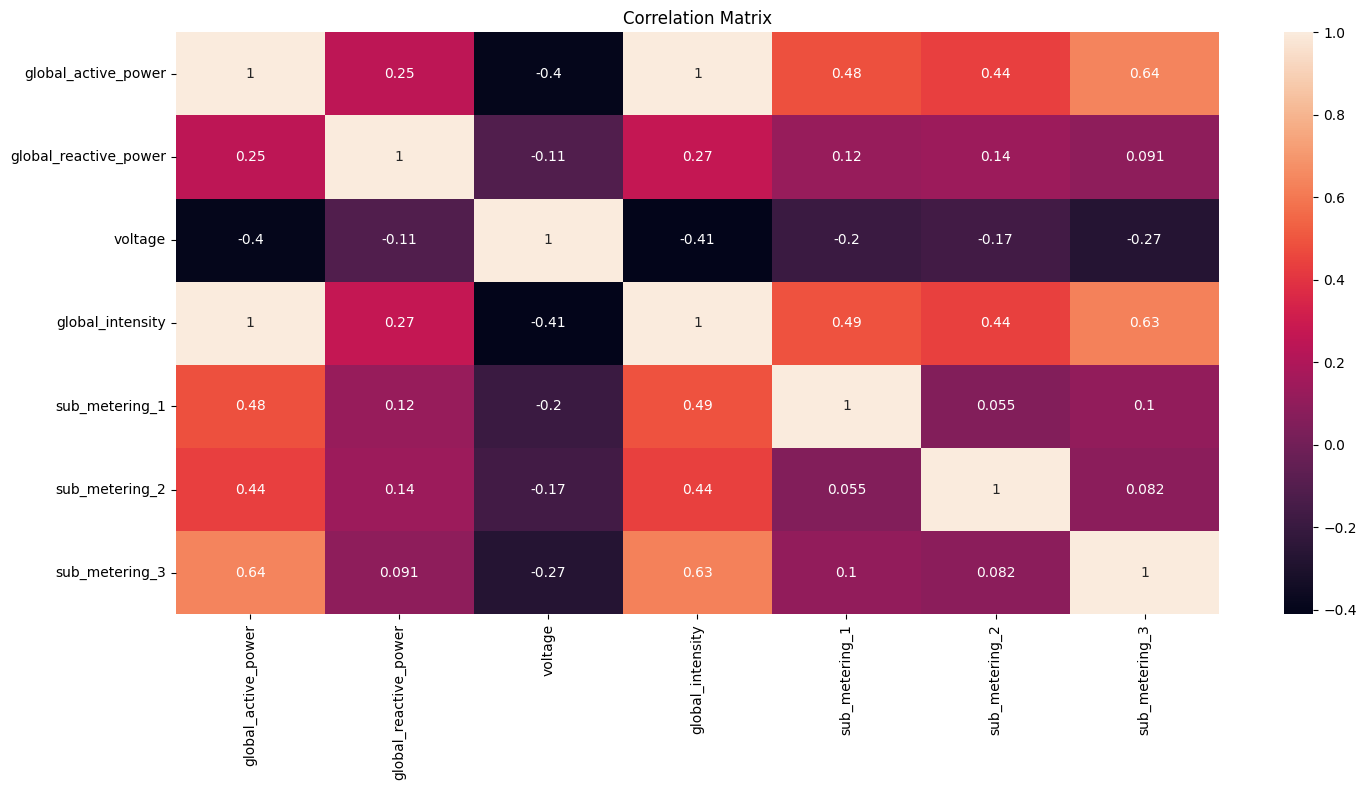

In [83]:
# Fill missing values with the median of each column before calculating correlation
sns.heatmap(df.fillna(df.median(numeric_only=True)).corr(), annot=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## Feature Analysis

Text(0.5, 1.0, 'Global Reactive Power')

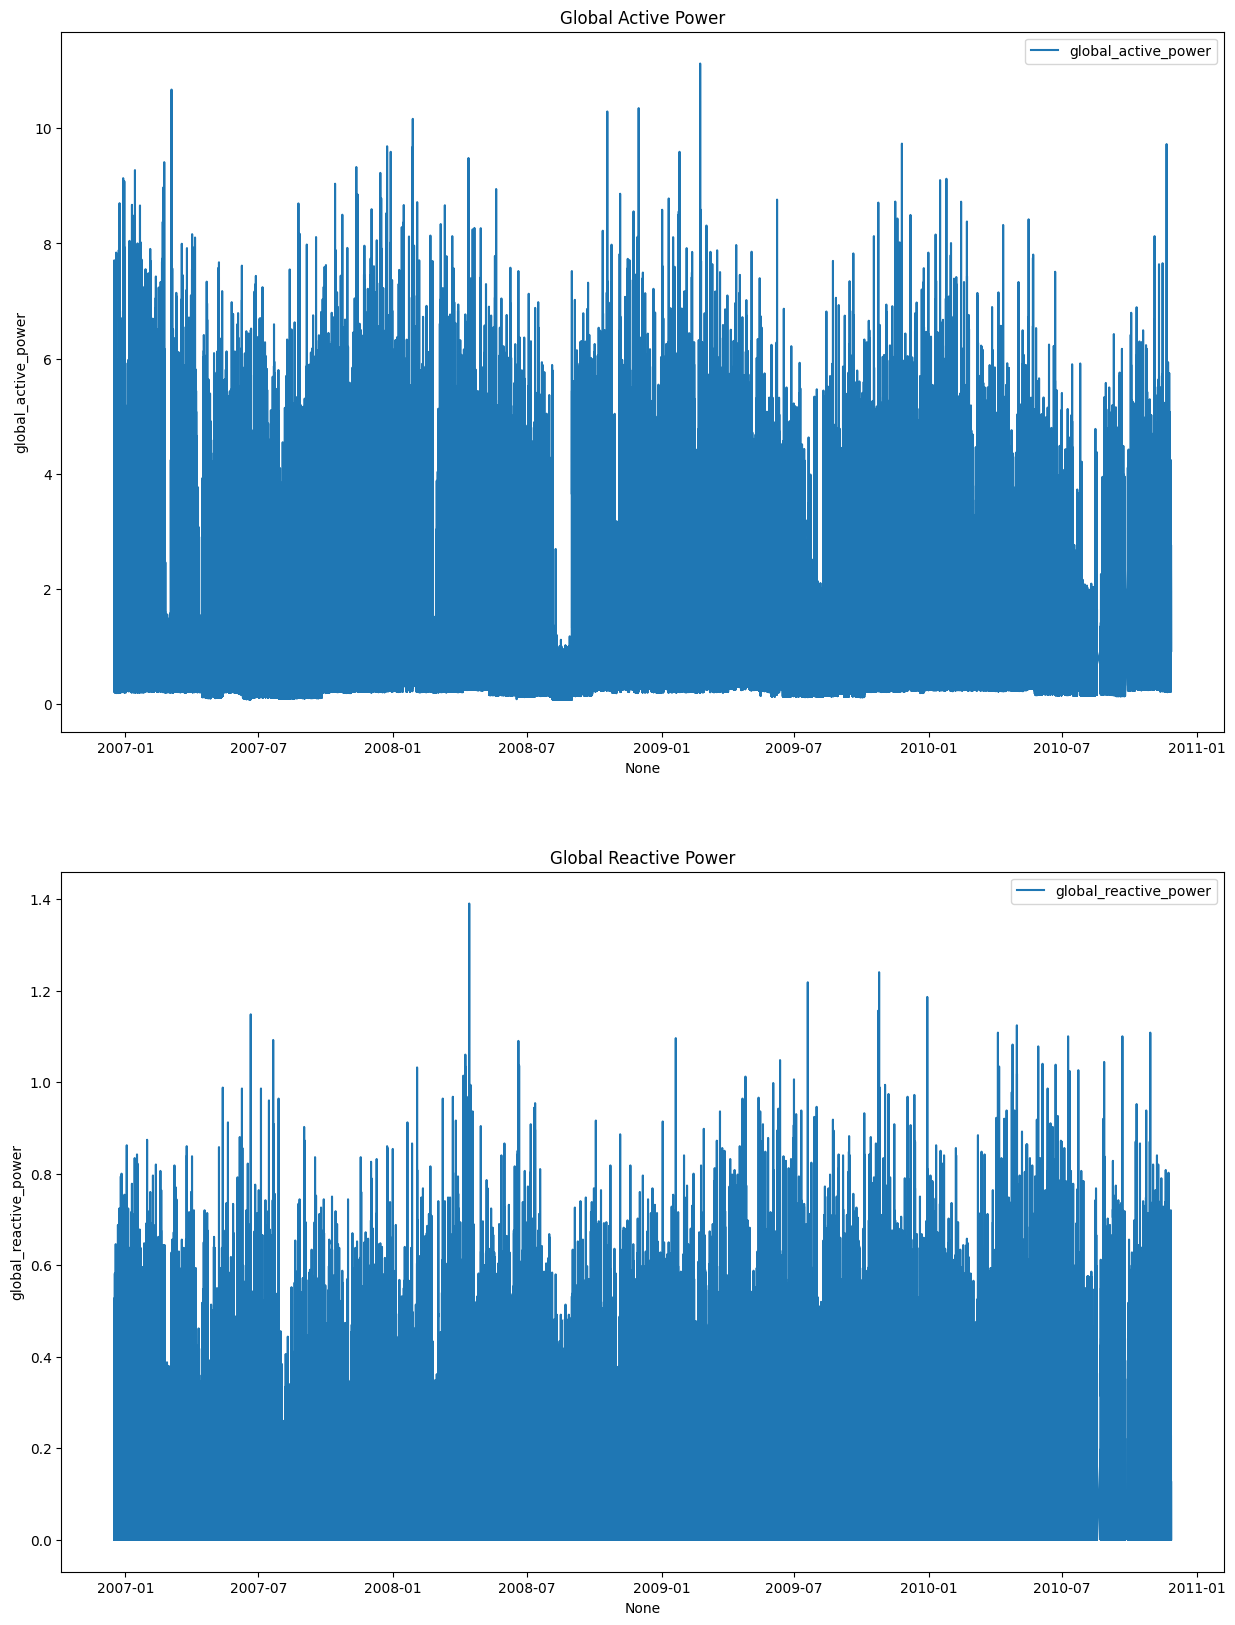

In [89]:
fig, axes = plt.subplots(2, 1, figsize=(15, 20))

sns.lineplot(data=df, x=df.index, y='global_active_power', label='global_active_power', ax=axes[0])
axes[0].set_title('Global Active Power')
sns.lineplot(data=df, x=df.index, y='global_reactive_power', label='global_reactive_power', ax=axes[1])
axes[1].set_title('Global Reactive Power')
# sns.lineplot(data=df, x='timestamp', y='L1_app_power', label='L1_app_power', ax=axes[2])
# axes[2].set_title('L1_app_power');

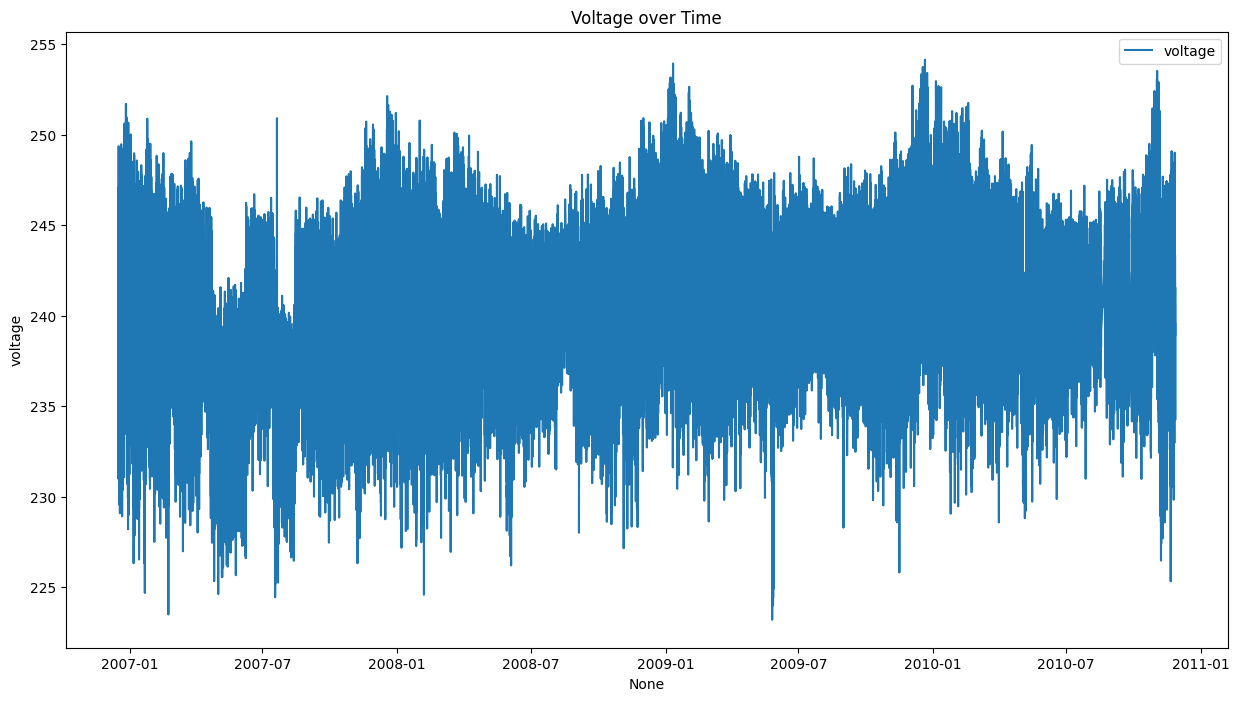

In [90]:
sns.lineplot(data=df, x=df.index, y='voltage', label='voltage')
plt.title('Voltage over Time');

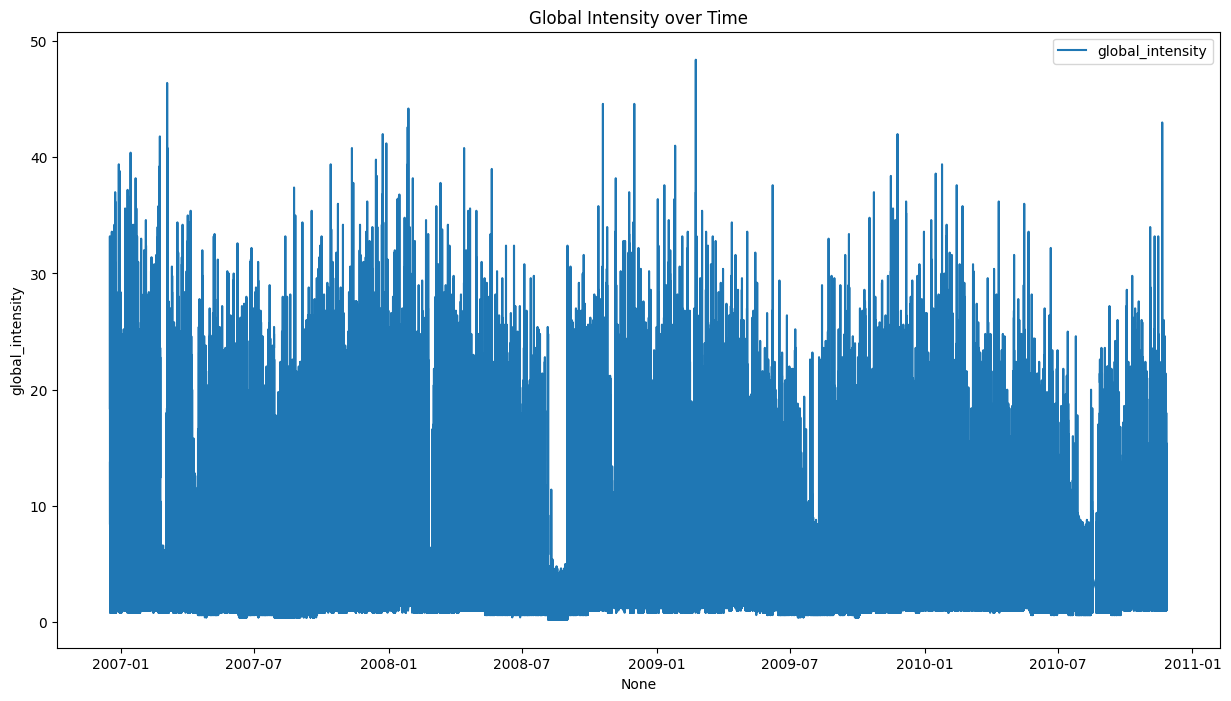

In [91]:
sns.lineplot(data=df, x=df.index, y='global_intensity', label='global_intensity')
plt.title('Global Intensity over Time');

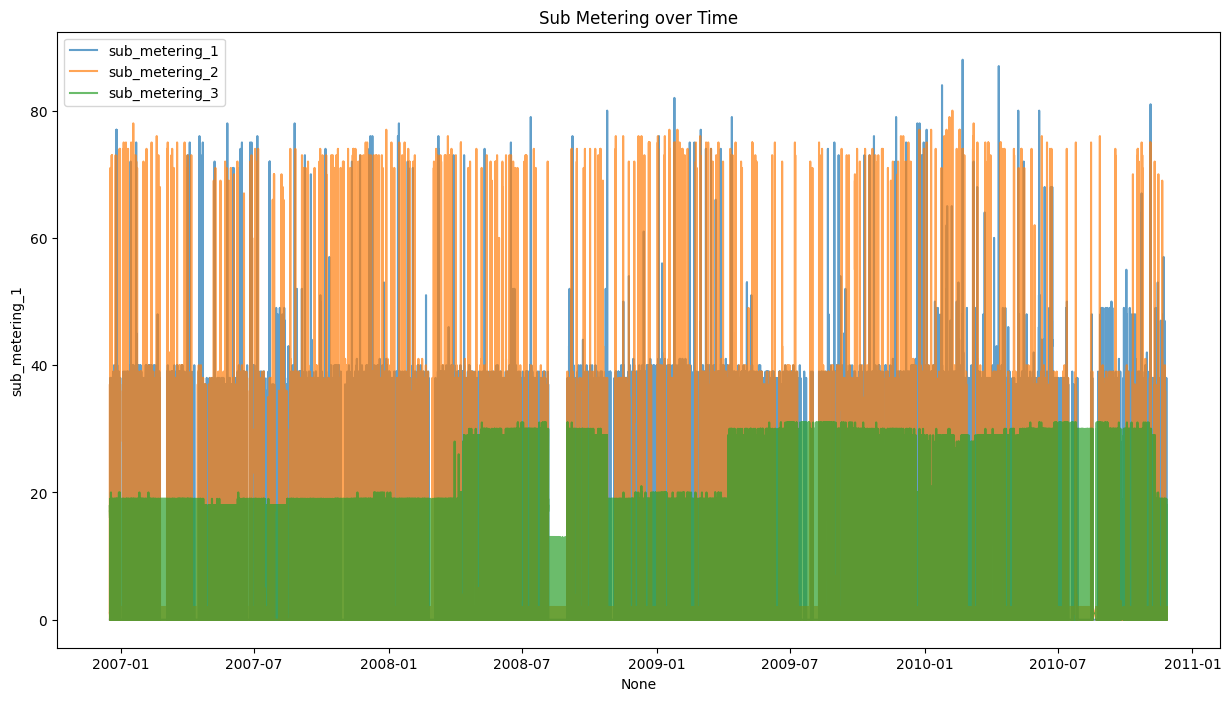

In [93]:
sns.lineplot(data=df, x=df.index, y='sub_metering_1', label='sub_metering_1', alpha=0.7)
sns.lineplot(data=df, x=df.index, y='sub_metering_2', label='sub_metering_2', alpha=0.7)
sns.lineplot(data=df, x=df.index, y='sub_metering_3', label='sub_metering_3', alpha=0.7)
plt.title('Sub Metering over Time');
plt.legend();

## Peaks detection

In [94]:
from scipy.signal import find_peaks

def normalize_zscore(y):
    return (y - np.mean(y)) / np.std(y)

def robust_zscore(y):
    y = np.array(y)
    med = np.median(y)
    mad = np.median(np.abs(y - med))
    return (y - med) / (mad if mad > 1e-6 else 1)

def plot_spikes_and_drops(x, y, title="Signal with Spikes and Drops", prominence=1.0, robust=False):

    if robust:
        y_pred_norm = robust_zscore(y)
    else:
        y_pred_norm = normalize_zscore(y)
    peaks, _ = find_peaks(y_pred_norm, prominence=prominence)  # use normalized threshold
    drops, _ = find_peaks(-y_pred_norm, prominence=prominence)  # use normalized threshold

    plt.figure(figsize=(15, 9))
    plt.plot(x, y, label="Signal", color="gray")
    plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
    plt.plot(x[drops], y[drops], "bv", label="Drops")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_20712\555613157.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
C:\Users\HP\AppData\Local\Temp\ipykernel_20712\555613157.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[drops], y[drops], "bv", label="Drops")


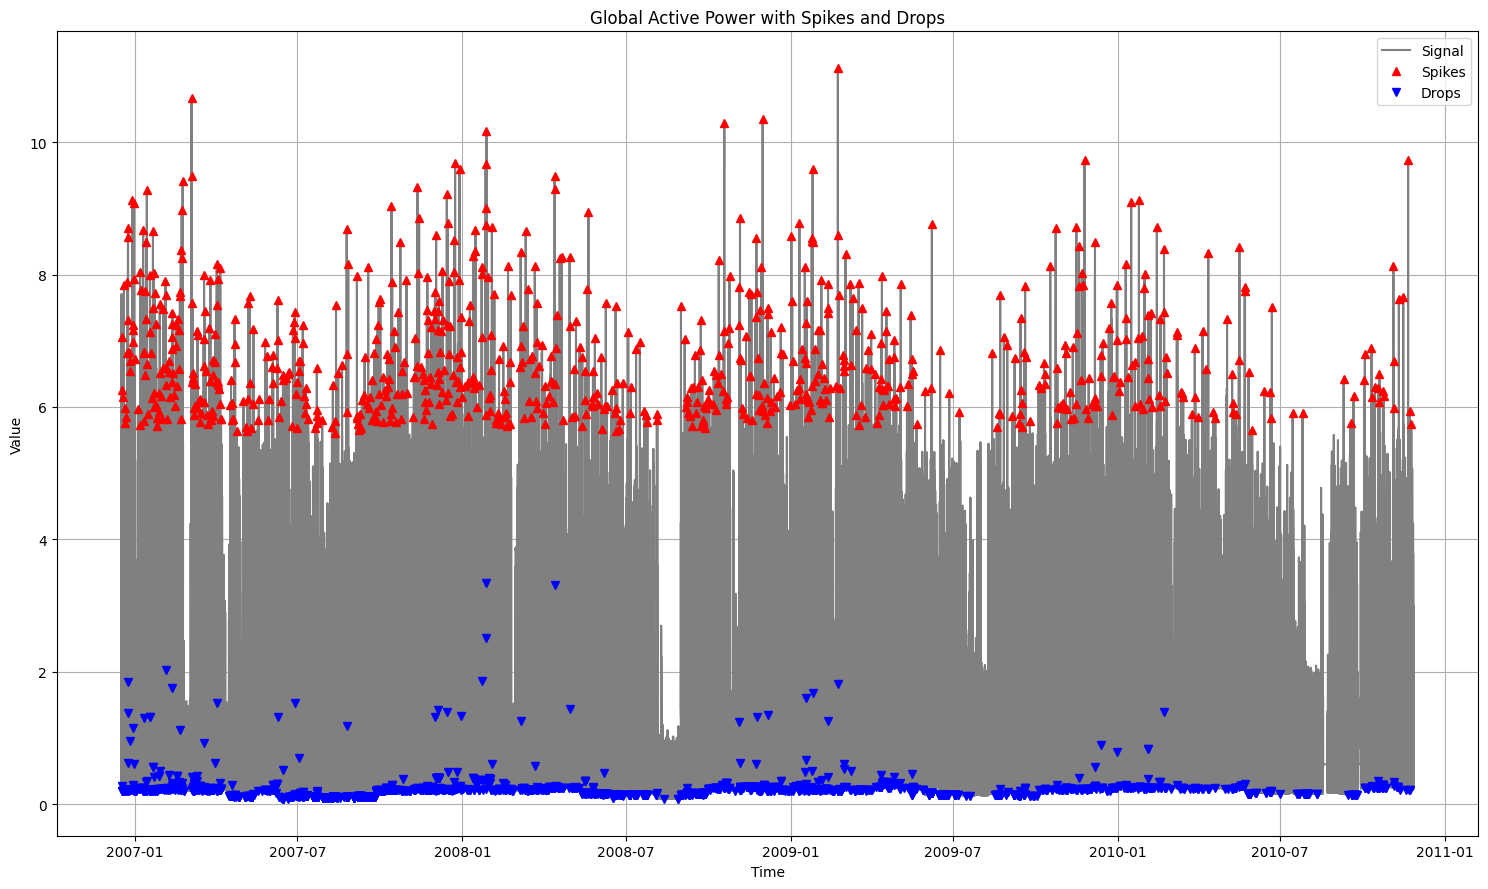

In [100]:
plot_spikes_and_drops(df.index,
                      df['global_active_power'].fillna(df['global_active_power'].median()), 
                      title="Global Active Power with Spikes and Drops",
                      prominence=14.0, robust=True)

## Hourly Analysis

In [101]:
# Group by hour
df_hour = df.groupby(df.index.floor('h'))

# Create index for full time range
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df_hour.indices.keys()).min(),
        pd.DatetimeIndex(df_hour.indices.keys()).max(), 
        freq='h'
    )
)

# Join with hourly aggregated data
act_pow_hour_endog = full_range.join(df_hour['global_active_power'].mean(), how='left').squeeze()

In [102]:
df_hour.count().describe()

,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
count,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000,34589.000000
mean,59.246581,59.246581,59.246581,59.246581,59.246581,59.246581,59.246581
std,6.636243,6.636243,6.636243,6.636243,6.636243,6.636243,6.636243
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
50%,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
75%,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
max,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000


In [103]:
def plot_hourly_data(series, title, color='blue'):
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else -100
    
     
    sns.lineplot(series.fillna(fill_value), label=f'hourly {title}', color=color)
    
    # Mark missing values
    plt.scatter(
        x=series[series.isna()].index,
        y=[series.min()-0.01]*series[series.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"Hourly {title}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Separate by phase

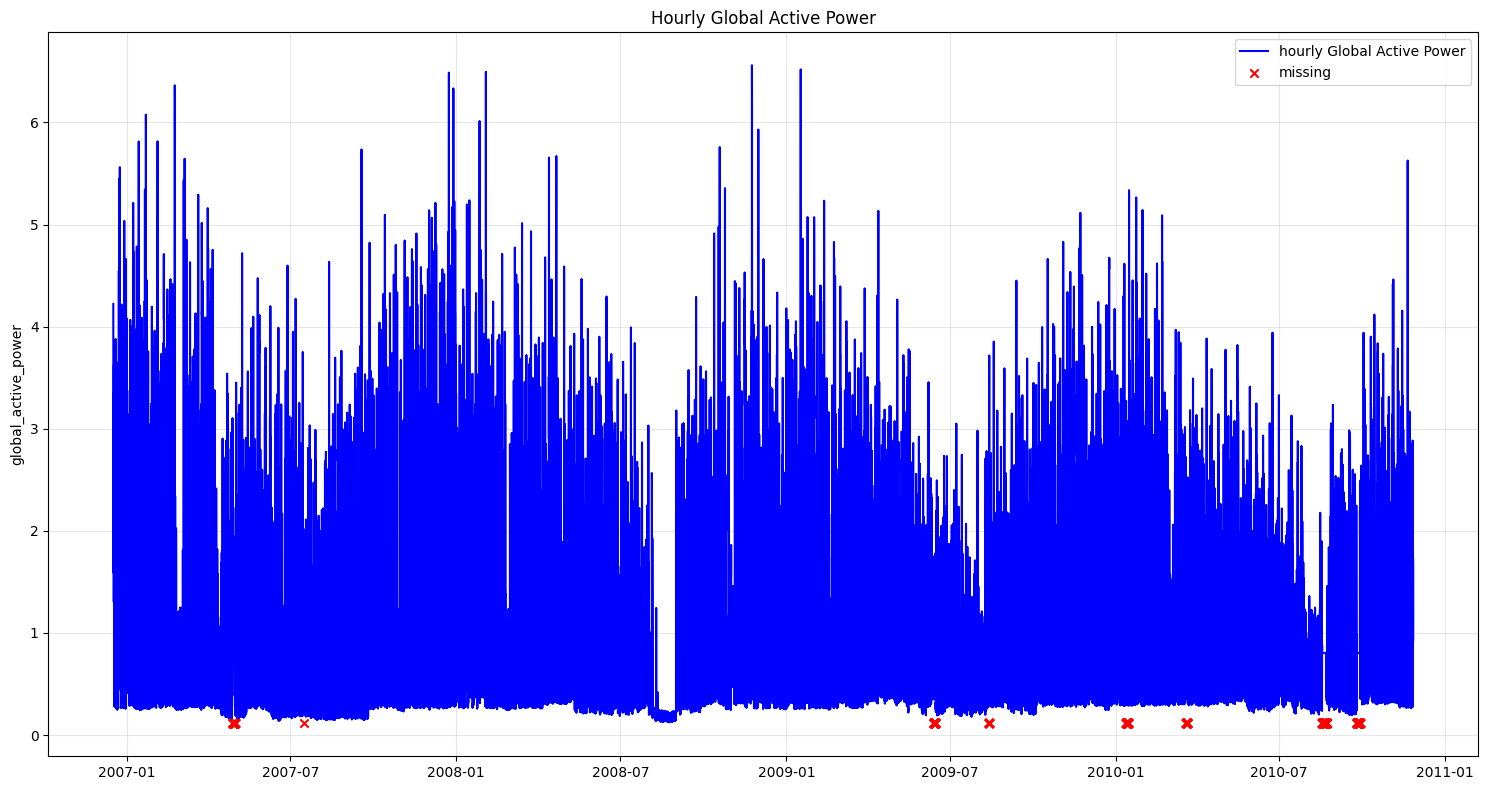

In [105]:
plot_hourly_data(act_pow_hour_endog, 'Global Active Power')

### Detect peaks

C:\Users\HP\AppData\Local\Temp\ipykernel_20712\555613157.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
C:\Users\HP\AppData\Local\Temp\ipykernel_20712\555613157.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[drops], y[drops], "bv", label="Drops")


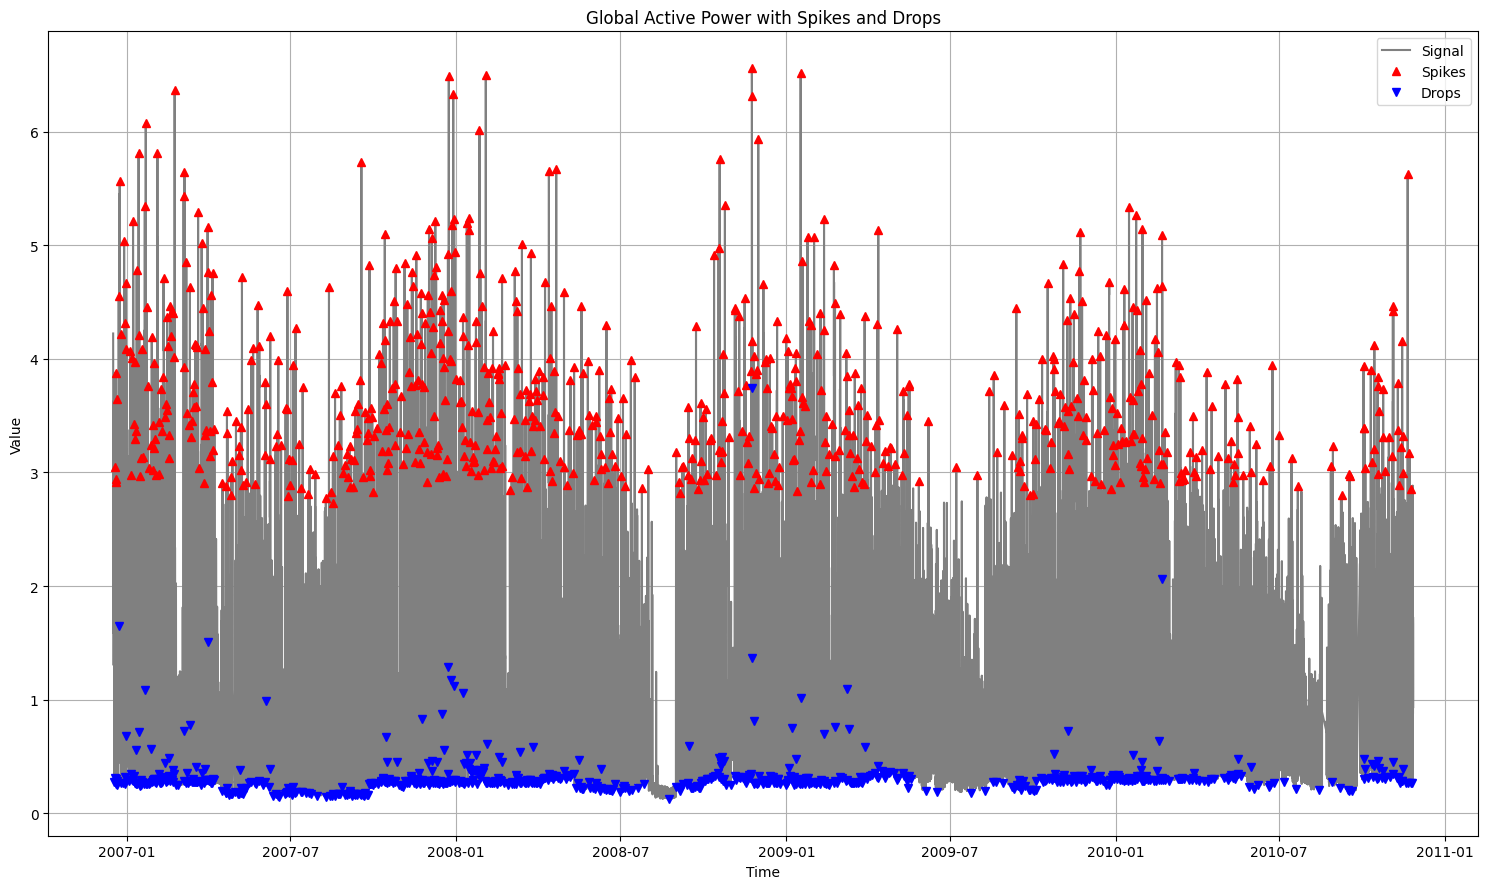

In [109]:
plot_spikes_and_drops(act_pow_hour_endog.dropna().index,
                      act_pow_hour_endog.dropna(), 
                      title="Global Active Power with Spikes and Drops",
                      prominence=5.0, robust=True)

### Weekly Patterns Analysis (based on hourly analysis)

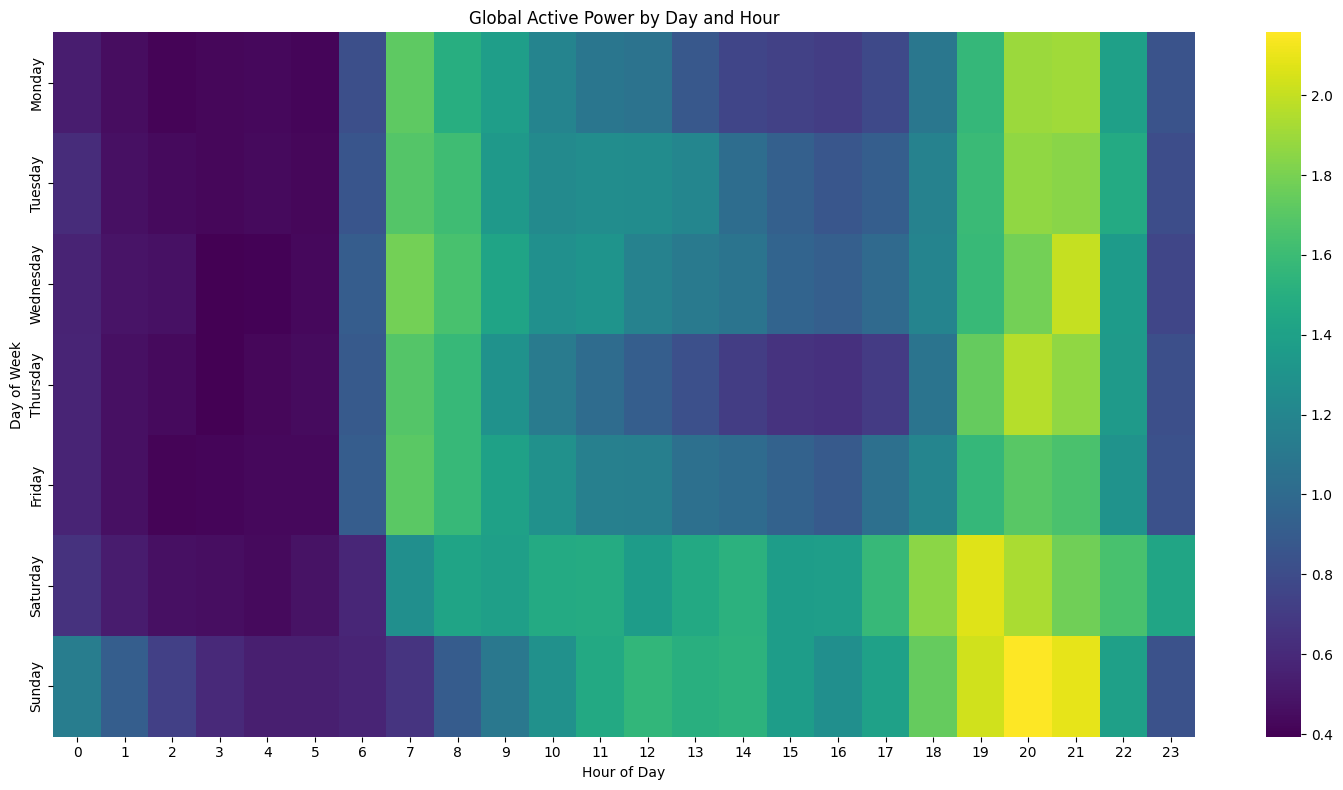

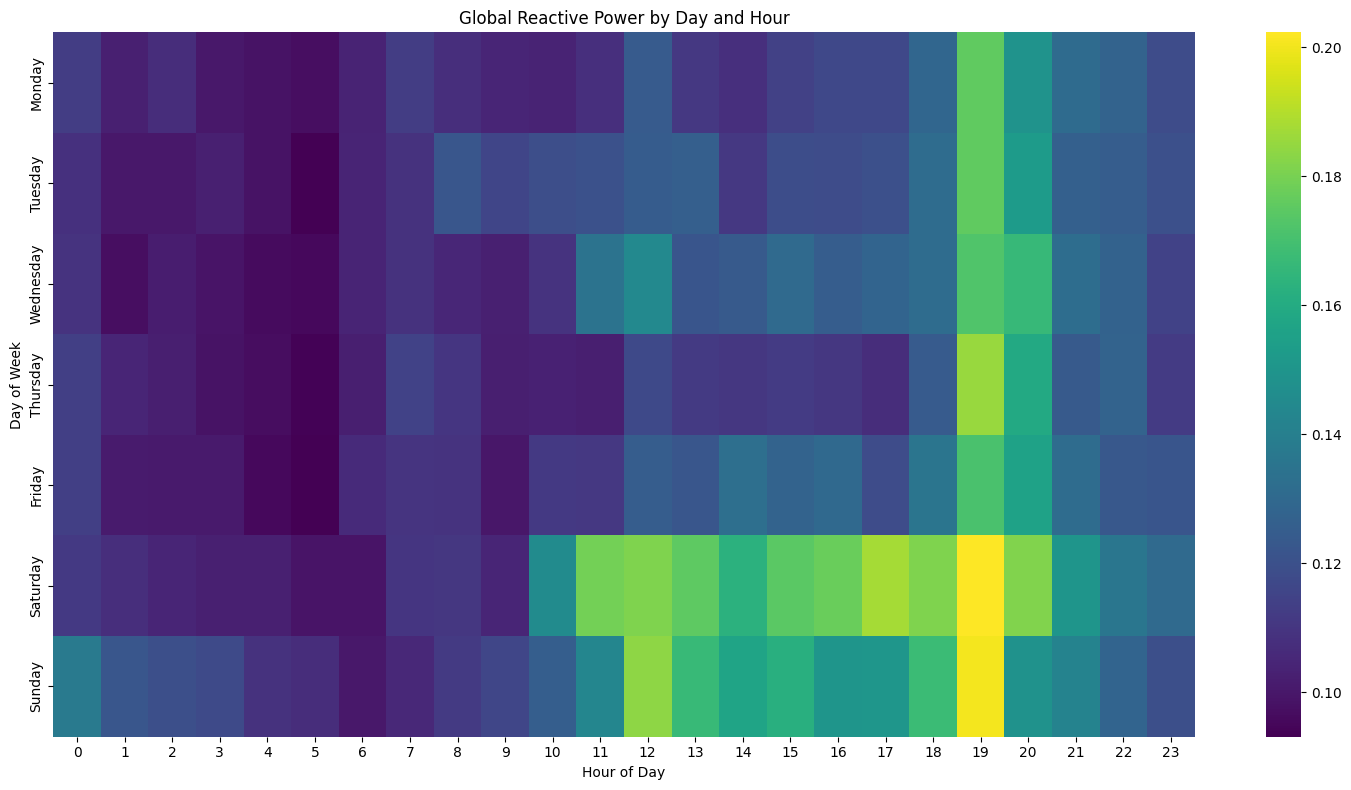

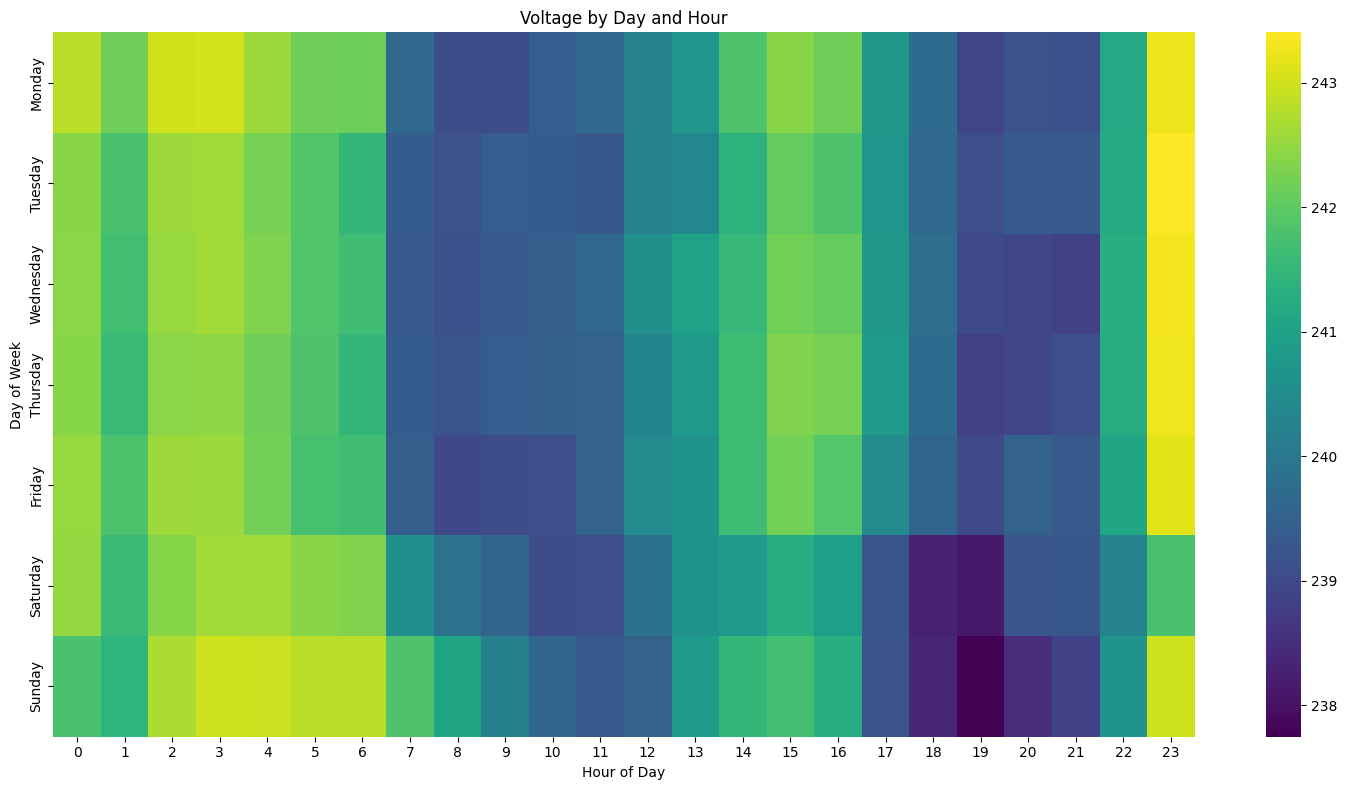

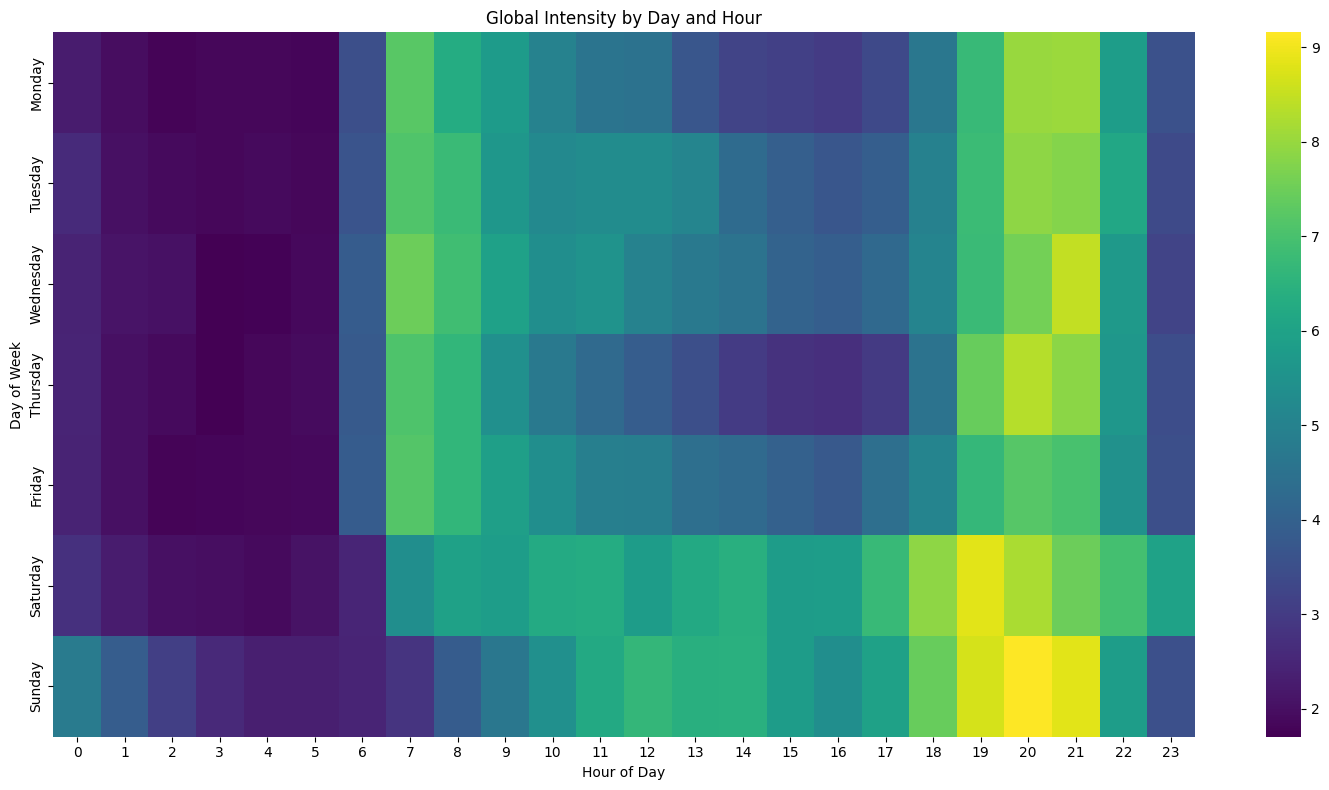

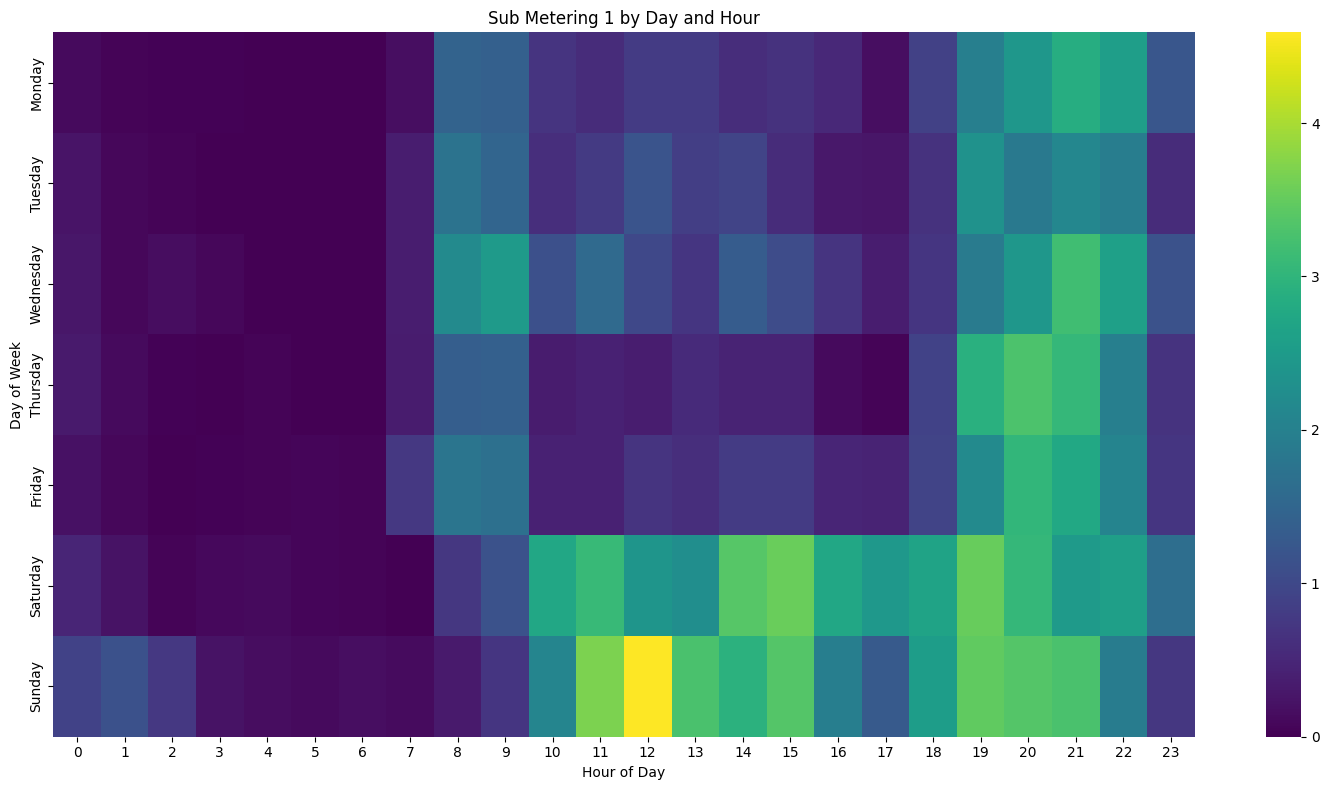

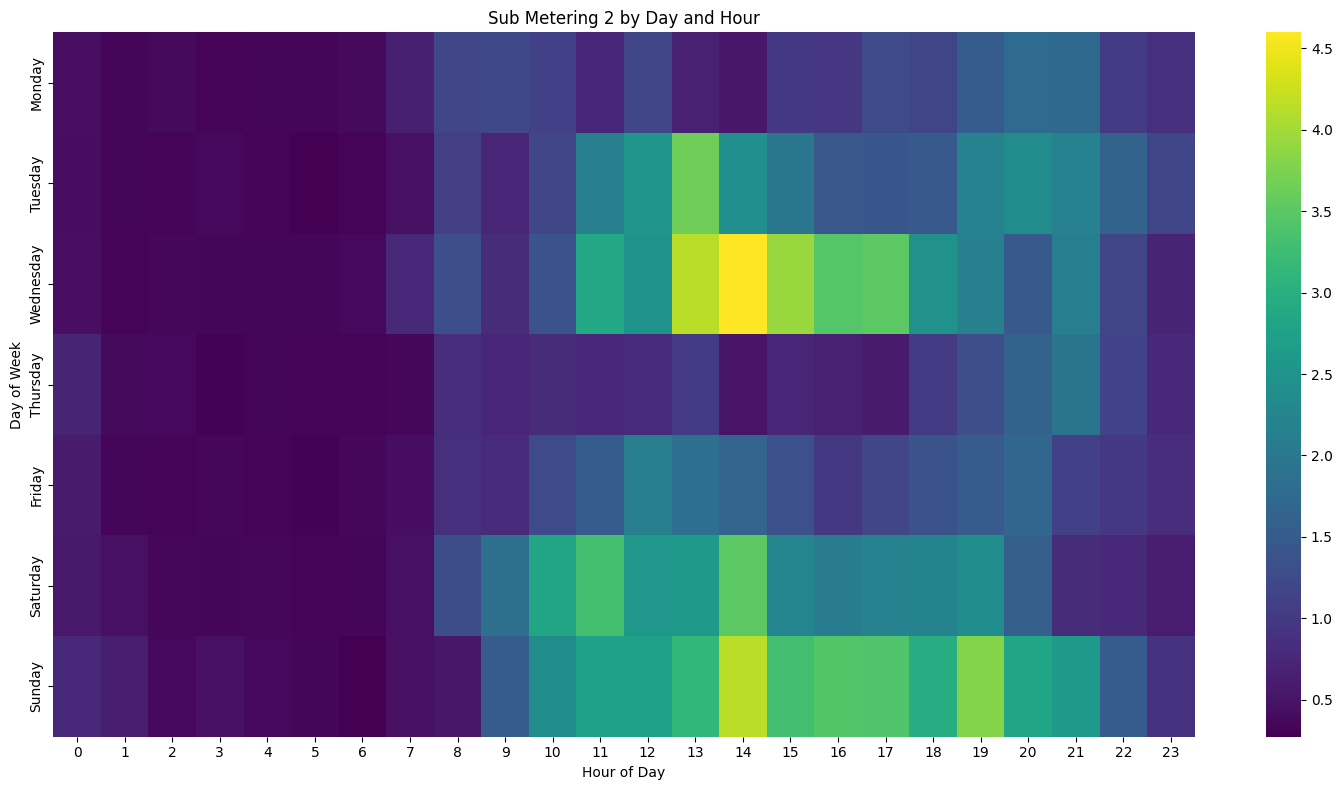

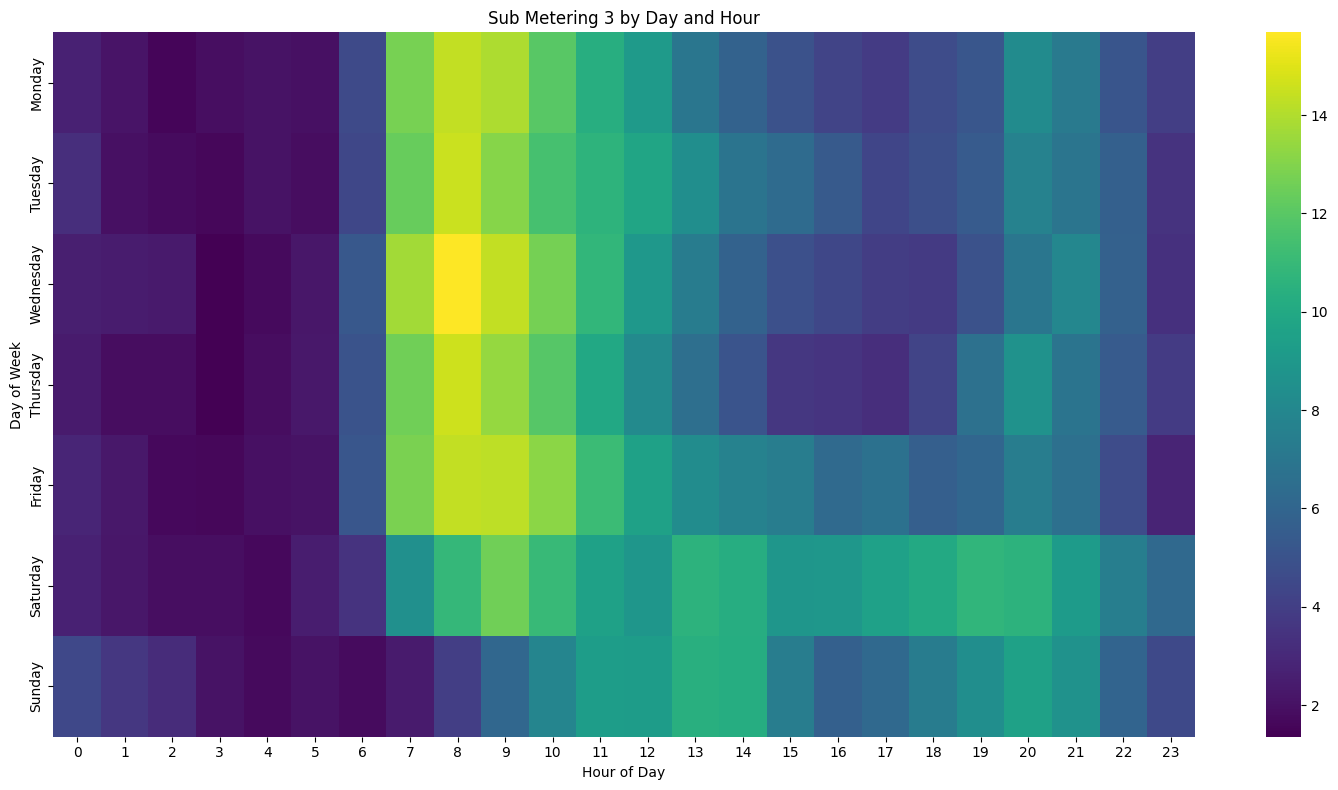

ValueError: could not convert string to float: 'Monday'

In [114]:
# Extract day of week and hour
df['day_of_week'] = df.index.day_name()
df['hour'] = df.index.hour

# Group by day of week and hour
daily_patterns = df.groupby(['day_of_week', 'hour']).agg({
    'global_active_power': 'mean',
    'global_reactive_power': 'mean',
    'global_intensity': 'mean',
    'voltage': 'mean',
    'sub_metering_1': 'mean',
    'sub_metering_2': 'mean',
    'sub_metering_3': 'mean'
}).reset_index()

# Order days correctly
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_patterns['day_of_week'] = pd.Categorical(daily_patterns['day_of_week'], categories=day_order, ordered=True)
daily_patterns = daily_patterns.sort_values(['day_of_week', 'hour'])

# Plot heatmap for each column
for column in df.columns:
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values=column)
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title(f'{column.replace("_", " ").title()} by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

### Autocorrelation Analysis

<Figure size 1500x600 with 0 Axes>

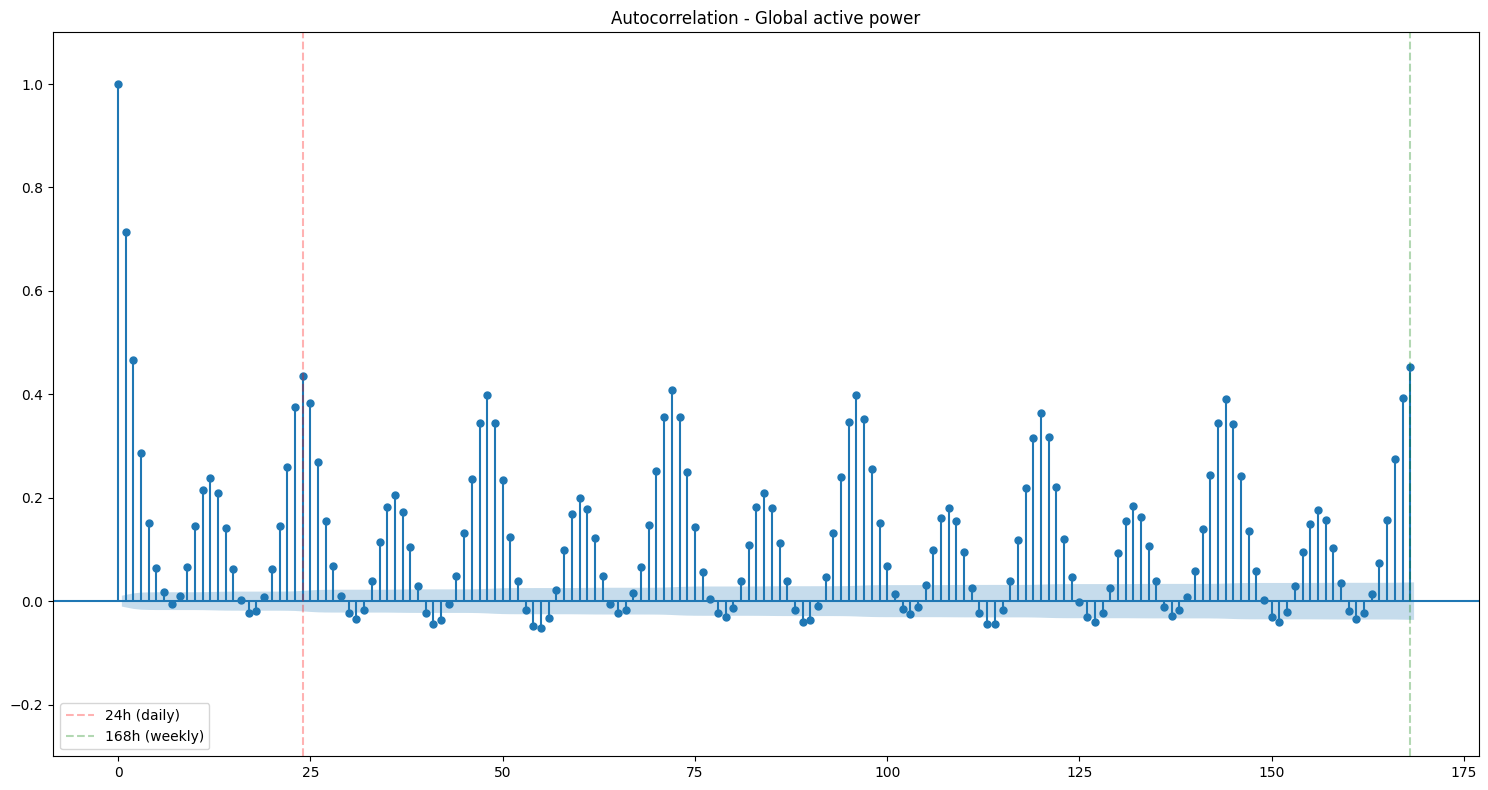

<Figure size 1500x600 with 0 Axes>

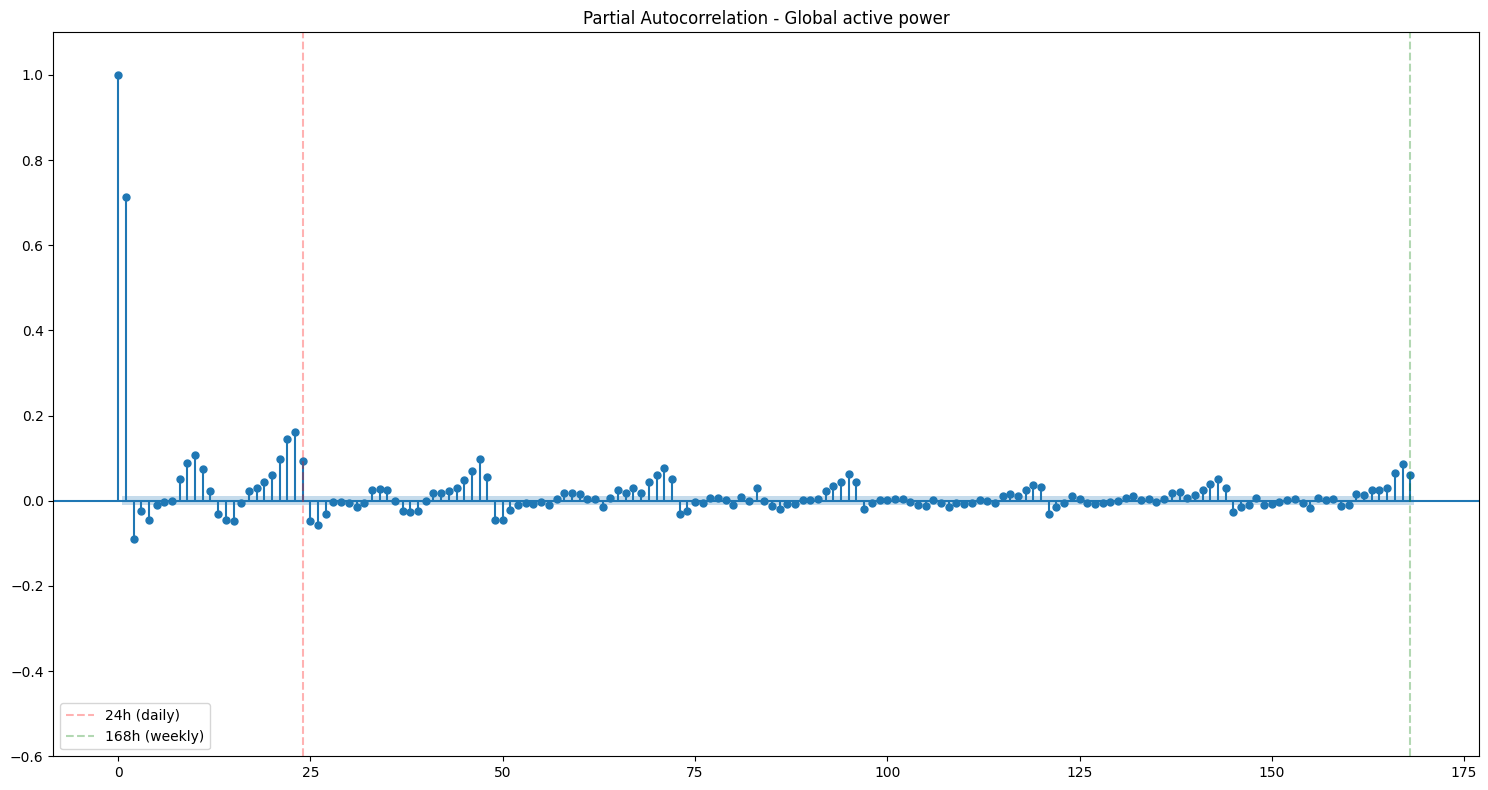

In [115]:
def plot_acf_pacf(series, lags, phase_label):
    fill_value = series.median() if not pd.isna(series.median()) else -100
    filled_series = series.fillna(fill_value)
    
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Autocorrelation - {phase_label} active power')
    plt.ylim(-0.3, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Partial Autocorrelation - {phase_label} active power')
    plt.ylim(-0.6, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_acf_pacf(act_pow_hour_endog, lags=24*7, phase_label='Global')

## 15-min Analysis

In [117]:
# Group by 15-minute intervals
df_15min = df.groupby(df.index.floor('15min'))

# Create index for full time range
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df_15min.indices.keys()).min(),
        pd.DatetimeIndex(df_15min.indices.keys()).max(), 
        freq='15min'
    )
)

# Join with hourly aggregated data for each phase
act_pow_15m_endog = full_range.join(df_15min['global_active_power'].mean(), how='left').squeeze()

In [118]:
df_15min.count().describe()

,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3,day_of_week,hour
count,138352.000000,138352.000000,138352.000000,138352.000000,138352.000000,138352.000000,138352.000000,138352.000000,138352.000000
mean,14.812074,14.812074,14.812074,14.812074,14.812074,14.812074,14.812074,14.999848,14.999848
std,1.663501,1.663501,1.663501,1.663501,1.663501,1.663501,1.663501,0.040327,0.040327
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,3.000000
25%,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000
50%,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000
75%,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000
max,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000


In [119]:
def plot_15m_data(series, title, color='blue'):
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else -100
    
     
    sns.lineplot(series.fillna(fill_value), label=f'15min {title}', color=color)
    
    # Mark missing values
    plt.scatter(
        x=series[series.isna()].index,
        y=[series.min()-0.01]*series[series.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"15-min {title}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Separate by phase

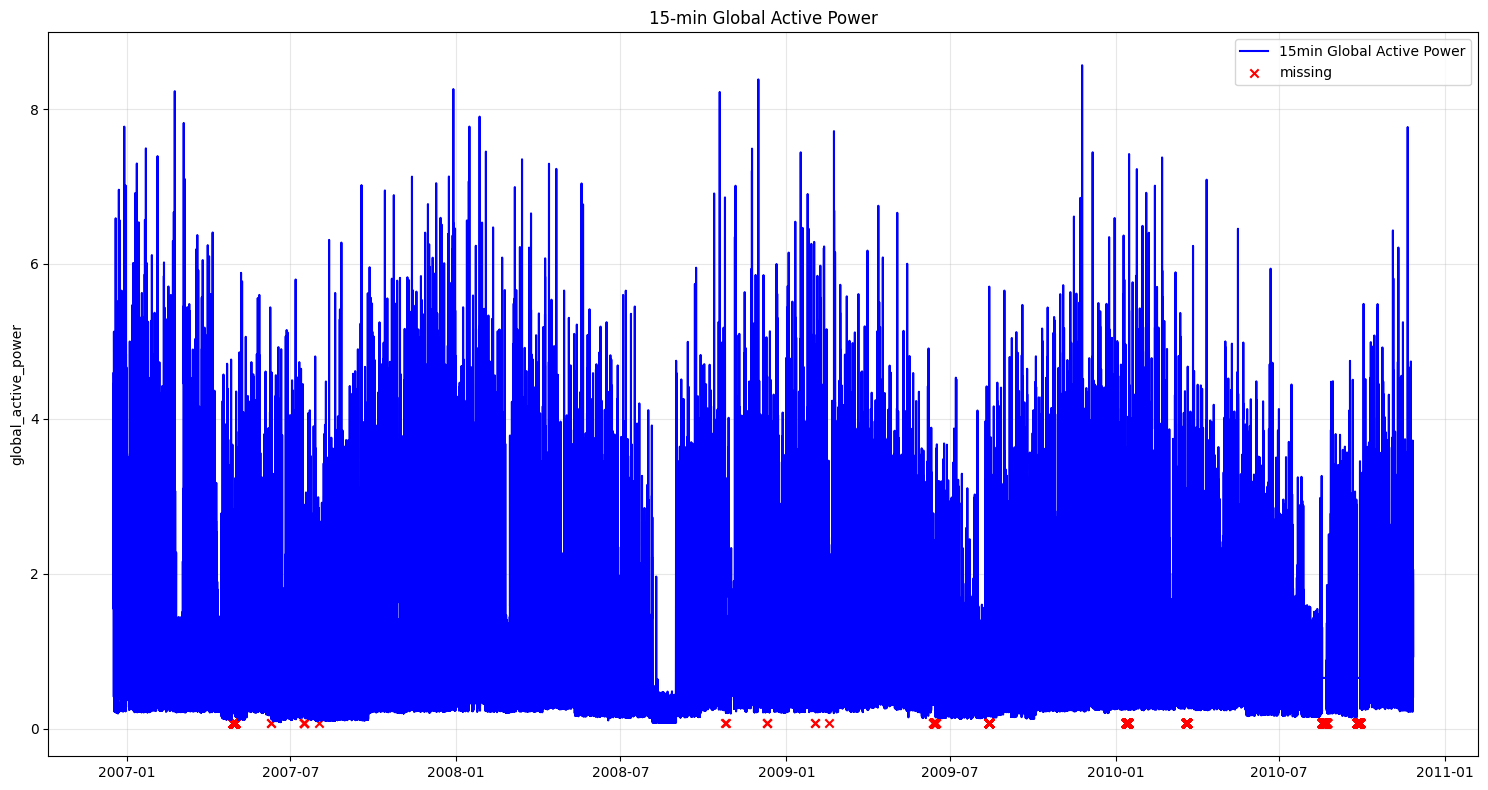

In [120]:
plot_15m_data(act_pow_15m_endog, 'Global Active Power')

### Detect peaks

C:\Users\HP\AppData\Local\Temp\ipykernel_20712\555613157.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
C:\Users\HP\AppData\Local\Temp\ipykernel_20712\555613157.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[drops], y[drops], "bv", label="Drops")


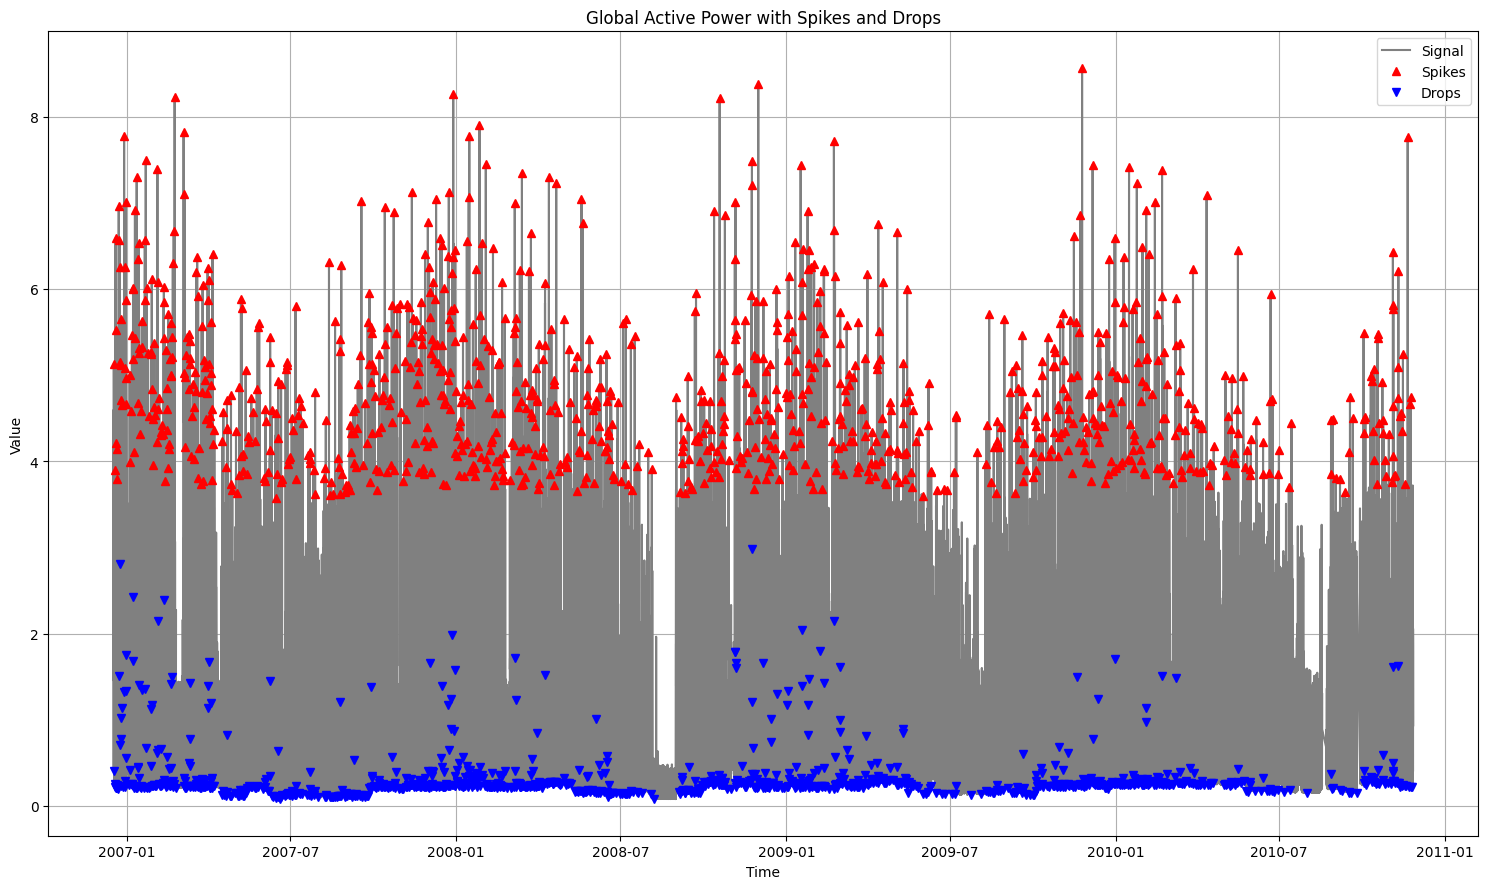

In [122]:
plot_spikes_and_drops(act_pow_15m_endog.dropna().index,
                      act_pow_15m_endog.dropna(), 
                      title="Global Active Power with Spikes and Drops",
                      prominence=8, robust=True)

### Autocorrelation Analysis

<Figure size 1500x600 with 0 Axes>

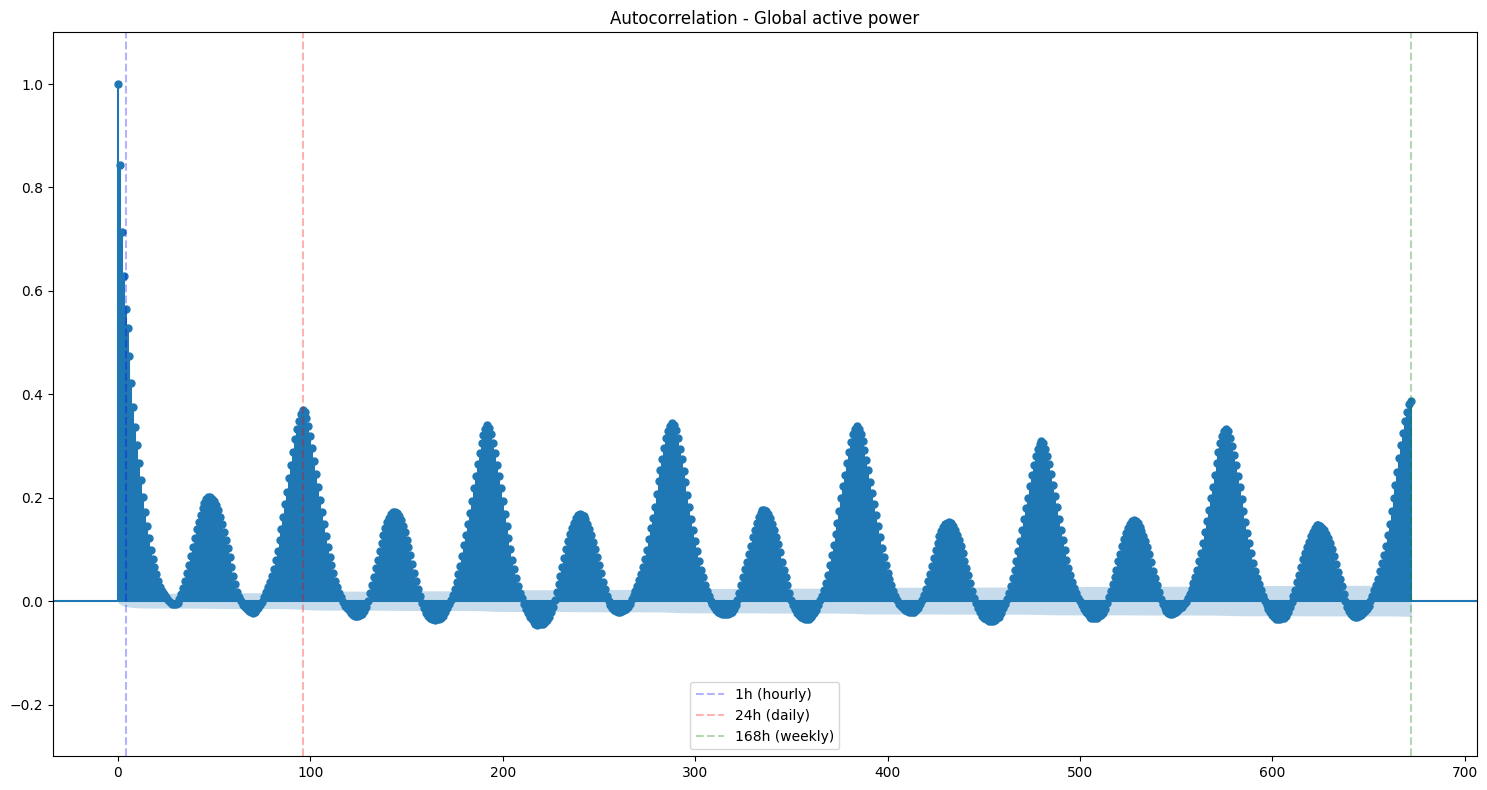

<Figure size 1500x600 with 0 Axes>

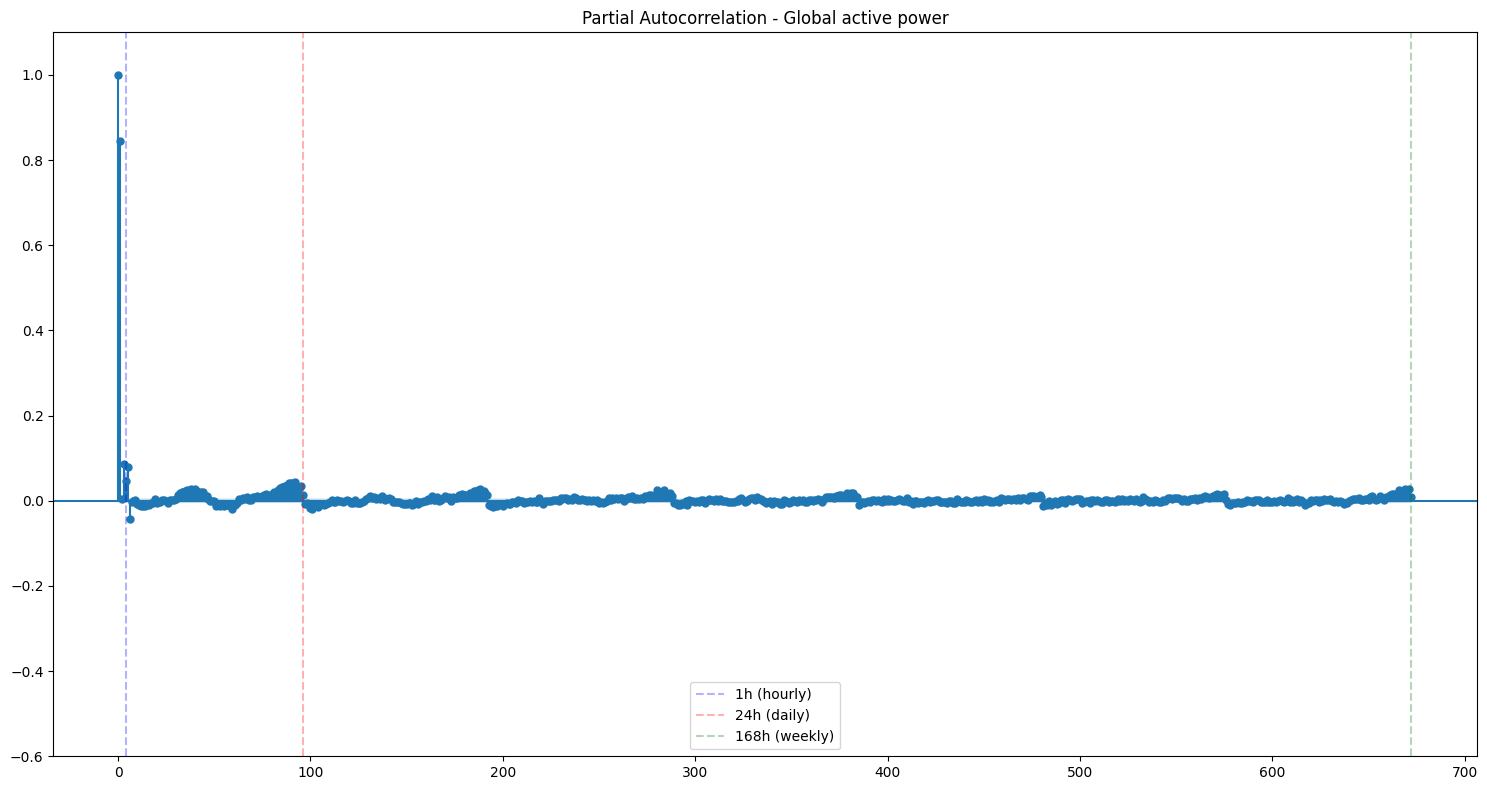

In [123]:
def plot_acf_pacf(series, lags, phase_label):
    fill_value = series.median() if not pd.isna(series.median()) else -100
    filled_series = series.fillna(fill_value)
    
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Autocorrelation - {phase_label} active power')
    plt.ylim(-0.3, 1.1)
    plt.axvline(x=4, color='b', linestyle='--', alpha=0.3, label='1h (hourly)')
    plt.axvline(x=24*4, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7*4, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Partial Autocorrelation - {phase_label} active power')
    plt.ylim(-0.6, 1.1)
    plt.axvline(x=4, color='b', linestyle='--', alpha=0.3, label='1h (hourly)')
    plt.axvline(x=24*4, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7*4, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Active Power ACF/PACF
plot_acf_pacf(act_pow_15m_endog, lags=24*7*4, phase_label='Global')